<img src="https://raw.githubusercontent.com/harmonize-tools/socio4health/main/docs/source/_static/image.png" alt="image info" height="100" width="100"/>


# Hands-on with socio4health: socioeconomic and demographic variables on dengue incidence in Colombia


**Run the tutorial via free cloud platforms:** [![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/harmonize-tools/socio4health/HEAD?urlpath=%2Fdoc%2Ftree%2Fnotebooks%2Fexample_colombia.ipynb) <a target="_blank" href="https://colab.research.google.com/github/harmonize-tools/socio4health/blob/main/notebooks/example_colombia.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

This notebook provides you with a real world example on how to use **socio4health** to **retrieve**, **harmonize** and **analyze** **socioeconomic and demographic** variables related to **dengue** incidence in Colombia and recreate the dataset used in the publication *Exploring Dengue Dynamics: A Multi-Scale Analysis of Spatio-Temporal Trends in Ibagué, Colombia* by Otelo et al., published in *Virus* in 2024 ([DOI](https://doi.org/10.3390/v16060906)). This tutorial assumes you have an **intermediate** or **advanced** understanding of **Python** and data manipulation.

## Setting up the environment

To run this notebook, you need to have the following prerequisites:

- **Python 3.10+**

Additionally, you need to install the `socio4health` and `pandas` package, which can be done using ``pip``:



In [ ]:
!pip install socio4health -q
!pip show socio4health

## Import Libraries

To perform the data extraction, the `socio4health` library provides the `Extractor` class for data extraction, and the `Harmonizer` class for data harmonization of the retrieved date. `pandas` will be used for data manipulation. Additionally, we will use some utility functions from the `socio4health.utils.harmonizer_utils` module to standardize and translate the dictionary.


In [2]:
import datetime
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from socio4health import Extractor
from socio4health.harmonizer import Harmonizer
from socio4health.utils import harmonizer_utils

## 1. Extract data from Colombia

To extract data from Colombia, use the `Extractor` class from the `socio4health` library. As in the publication, extract the Colombian National Population and Housing Census 2018 (**CNPV 2018**) dataset from the Colombian Nacional Administration of Statistics (**DANE**) website. The dataset is available at: https://microdatos.dane.gov.co/index.php/catalog/643/related-materials.

The `Extractor` class requires the following parameters:
- `input_path`: The `URL` or local path to the data source.
- `down_ext`: A list of file extensions to download. This can include `.CSV`, `.csv`, `.zip`, etc.
- `output_path`: The local path where the extracted data will be saved.
- `key_words`: A list of keywords to filter the files to be downloaded. In this case, we are only interested in the file `14045.zip`, which contains the data at the desired level of granularity (census block level or "Manzana").
- `depth`: The depth of the directory structure to traverse when downloading files. A depth of `0` means only the files in the specified directory will be downloaded.



In [3]:
col_online_extractor = Extractor(input_path="https://microdatos.dane.gov.co/index.php/catalog/643/related-materials",
                                 down_ext=['.cpg', '.dbf', '.prj','.sbn', '.sbx', '.shx', '.shp', '.zip'],
                                 output_path="data/example_colombia/raw",
                                 key_words=["14045.zip"],
                                 depth=0)
col_CNPV = col_online_extractor.s4h_extract()

15:36:25 INFO: Starting data extraction...
15:36:25 INFO: Extracting data in online mode...
15:36:25 INFO: Scraping URL: https://microdatos.dane.gov.co/index.php/catalog/643/related-materials with depth 0
15:36:27 INFO: Found 1 files to download
15:36:27 INFO: Downloading 1 files to 'data/example_colombia/raw'
Downloading: 100%|██████████| 1/1 [00:00<00:00,  4.47file/s]                      
15:36:27 INFO: Downloaded 1/1 files
Extracting: 100%|██████████| 1/1 [00:00<00:00, 285.72archive/s]  
15:36:27 INFO: Extracted 7 files from 1 archives
Reading: 100%|██████████| 7/7 [00:12<00:00,  1.81s/file]                                                                
15:36:40 INFO: Read 7/7 files
15:36:40 INFO: Extraction completed successfully.


In [4]:
col_CNPV[0]

,COD_DANE_A,DPTO_CCDGO,MPIO_CCDGO,MPIO_CDPMP,CLAS_CCDGO,SETR_CCDGO,SETR_CCNCT,SECR_CCDGO,SECR_CCNCT,ZU_CCDGO,...,TP51_13_ED,TP51_99_ED,CD_LC_CM,NMB_LC_CM,TP_LC_CM,Shape_Leng,Shape_Area,COD_RDTM,geometry,filename
0,0500210000000000010101,05,002,05002,1,000,050021000,00,05002100000,000,...,10.0,1.0,None,None,None,0.002298,2.038760e-07,050021990000000000010101,"POLYGON ((-75.42779 5.79423, -75.4278 5.79422,...",fa9c63b6_MGN_NivelManzana_Integrado_CNPV_MGN_A...
1,0500210000000000010102,05,002,05002,1,000,050021000,00,05002100000,000,...,19.0,4.0,None,None,None,0.003402,5.600867e-07,050021990000000000010102,"POLYGON ((-75.42719 5.79421, -75.42715 5.79415...",fa9c63b6_MGN_NivelManzana_Integrado_CNPV_MGN_A...
2,0500210000000000010103,05,002,05002,1,000,050021000,00,05002100000,000,...,6.0,1.0,None,None,None,0.002622,4.293780e-07,050021990000000000010103,"POLYGON ((-75.42804 5.79294, -75.42807 5.79291...",fa9c63b6_MGN_NivelManzana_Integrado_CNPV_MGN_A...
3,0500210000000000010104,05,002,05002,1,000,050021000,00,05002100000,000,...,11.0,2.0,None,None,None,0.002673,4.493171e-07,050021990000000000010104,"POLYGON ((-75.42853 5.79348, -75.4286 5.79342,...",fa9c63b6_MGN_NivelManzana_Integrado_CNPV_MGN_A...
4,0500210000000000010105,05,002,05002,1,000,050021000,00,05002100000,000,...,0.0,0.0,None,None,None,0.001338,8.776894e-08,050021990000000000010105,"POLYGON ((-75.4291 5.79393, -75.4291 5.79393, ...",fa9c63b6_MGN_NivelManzana_Integrado_CNPV_MGN_A...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
504991,9977320030102700010102,99,773,99773,2,003,997732003,01,99773200301,027,...,0.0,0.0,None,None,None,0.002270,2.451366e-07,997732990030102700010102,"POLYGON ((-69.85155 4.33427, -69.85149 4.33427...",fa9c63b6_MGN_NivelManzana_Integrado_CNPV_MGN_A...
504992,9977320030102700010103,99,773,99773,2,003,997732003,01,99773200301,027,...,0.0,0.0,None,None,None,0.002919,5.196303e-07,997732990030102700010103,"POLYGON ((-69.85227 4.33365, -69.85257 4.3337,...",fa9c63b6_MGN_NivelManzana_Integrado_CNPV_MGN_A...
504993,9977320030102700010104,99,773,99773,2,003,997732003,01,99773200301,027,...,0.0,0.0,None,None,None,0.002938,3.280837e-07,997732990030102700010104,"POLYGON ((-69.85276 4.33338, -69.85274 4.3336,...",fa9c63b6_MGN_NivelManzana_Integrado_CNPV_MGN_A...
504994,9977320030102700010105,99,773,99773,2,003,997732003,01,99773200301,027,...,0.0,0.0,None,None,None,0.002514,3.375903e-07,997732990030102700010105,"POLYGON ((-69.85313 4.33348, -69.85311 4.33368...",fa9c63b6_MGN_NivelManzana_Integrado_CNPV_MGN_A...


## 2. Load and standardize the dictionary
To harmonize the data, provide a dictionary that describes the variables in the dataset. The CNPV 2018 dictionary is available at [here](https://microdatos.dane.gov.co/index.php/catalog/643/download/14045). Follow the steps in the tutorial ["How to Create a Raw Dictionary for Data Harmonization"](https://harmonize-tools.github.io/socio4health/dictionary.html) to create a raw dictionary in Excel format.



In [5]:
raw_dic = pd.read_excel("inputs/raw_dic_mzn.xlsx")
raw_dic

,variable_name,type,size,question,description,value
0,COD_DANE_A,Text,22.0,"Código de manzana concatenado (departamento, m...",NaN,NaN
1,DPTO_CCDGO,Text,2.0,Código del departamento,NaN,NaN
2,MPIO_CCDGO,Text,3.0,Código del municipio,NaN,NaN
3,MPIO_CDPMP,Text,5.0,Código concatenado que identifica al municipio,NaN,NaN
4,CLAS_CCDGO,Text,1.0,"Código de la clase 1 cabecera municipal, 2 cen...",NaN,NaN
...,...,...,...,...,...,...
101,TP51_13_ED,Double,NaN,Conteo de personas donde el nivel educativo de...,Ninguno,NaN
102,TP51_99_ED,Double,NaN,Conteo de personas donde el nivel educativo de...,Sin información,NaN
103,CD_LC_CM,Text,10.0,Código de la localidad o comuna,NaN,NaN
104,NMB_LC_CM,Text,50.0,Nombre de la localidad o comuna,NaN,NaN


Standardize the dictionary using the `s4h_standardize_dict` function from the `harmonizer_utils` module. Then, translate it to English using the `s4h_translate_column` function from the same module (**Note**: The translation model is downloaded on first use and cached locally, so the first execution may take a few minutes). Finally, classify the variables into categories using a pre-trained **BERT model**.

In [6]:
dic = harmonizer_utils.s4h_standardize_dict(raw_dic)
dic = harmonizer_utils.s4h_translate_column(dic, "question", language="en")
dic = harmonizer_utils.s4h_translate_column(dic, "description", language="en")
dic = harmonizer_utils.s4h_translate_column(dic, "possible_answers", language="en")


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

15:36:56 INFO: question translated
15:36:59 INFO: description translated
15:36:59 INFO: possible_answers translated


In [7]:
dic = harmonizer_utils.s4h_classify_rows(dic, "question_en", "description_en", "possible_answers_en",
                                        new_column_name="category",
                                        MODEL_PATH="dirreno/harmonize_bert_finetuned_classifier")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

This is how the standardized and translated dictionary looks:

In [8]:
dic

,variable_name,type,size,question,description,value,possible_answers,question_en,description_en,possible_answers_en,category
0,VERSION,Long Integer,NaN,año de la información geográfica,NaN,NaN,NaN,year of geographical information,NaN,NaN,Identification
1,CTNENCUEST,Double,NaN,cantidad de encuestas cnpv 2018,NaN,NaN,NaN,number of surveys cnpv 2018,NaN,NaN,Identification
2,TP3_1_SI,Double,NaN,cantidad de encuestas que reportaron estar en ...,NaN,NaN,NaN,number of surveys reported to be in ethnic ter...,NaN,NaN,Identification
3,TP3A_RI,Double,NaN,cantidad de encuestas que reportaron estar en ...,resguardo indígena,NaN,NaN,number of surveys reported to be in ethnic ind...,protection of indigenous peoples,NaN,Identification
4,TP3B_TCN,Double,NaN,cantidad de encuestas que reportaron estar en ...,tccn,NaN,NaN,number of surveys reported to be in ethnic ter...,ccn,NaN,Identification
...,...,...,...,...,...,...,...,...,...,...,...
101,DATO_ANM,Text,50.0,nombre capa anonimizada,NaN,NaN,NaN,anonymized layer name,NaN,NaN,Identification
102,NMB_LC_CM,Text,50.0,nombre de la localidad o comuna,NaN,NaN,NaN,name of town or commune,NaN,NaN,Business
103,TP27_PERSO,Double,NaN,número de personas,NaN,NaN,NaN,number of persons,NaN,NaN,Identification
104,DENSIDAD,Double,NaN,número promedio de habitantes en la manzana qu...,NaN,NaN,NaN,average number of inhabitants in the block liv...,NaN,NaN,Housing


## 3. Harmonize the data

Use the `Harmonizer` class from the **socio4health** library to harmonize the data.

The available columns in the dataset can be checked using the `s4h_get_available_columns` method. This method takes a list of DataFrames as input and **returns a list of column names that are present in the DataFrames**.

In [9]:
har = Harmonizer()
available_columns = har.s4h_get_available_columns(col_CNPV)
available_columns

['AG_CCDGO',
 'AREA',
 'CD_LC_CM',
 'CLAS_CCDGO',
 'COD_DANE_A',
 'COD_RDTM',
 'CTNENCUEST',
 'DATO_ANM',
 'DENSIDAD',
 'DPTO_CCDGO',
 'FILENAME',
 'GEOMETRY',
 'LATITUD',
 'LONGITUD',
 'MANZ_CCDGO',
 'MPIO_CCDGO',
 'MPIO_CDPMP',
 'NMB_LC_CM',
 'PERSONAS_L',
 'PERSONAS_S',
 'SECR_CCDGO',
 'SECR_CCNCT',
 'SECU_CCDGO',
 'SECU_CCNCT',
 'SETR_CCDGO',
 'SETR_CCNCT',
 'SETU_CCDGO',
 'SETU_CCNCT',
 'SHAPE_AREA',
 'SHAPE_LENG',
 'TP14_1_TIP',
 'TP14_2_TIP',
 'TP14_3_TIP',
 'TP14_4_TIP',
 'TP14_5_TIP',
 'TP14_6_TIP',
 'TP15_1_OCU',
 'TP15_2_OCU',
 'TP15_3_OCU',
 'TP15_4_OCU',
 'TP16_HOG',
 'TP19_ACU_1',
 'TP19_ACU_2',
 'TP19_ALC_1',
 'TP19_ALC_2',
 'TP19_EE_1',
 'TP19_EE_2',
 'TP19_EE_E1',
 'TP19_EE_E2',
 'TP19_EE_E3',
 'TP19_EE_E4',
 'TP19_EE_E5',
 'TP19_EE_E6',
 'TP19_EE_E9',
 'TP19_GAS_1',
 'TP19_GAS_2',
 'TP19_GAS_9',
 'TP19_INTE1',
 'TP19_INTE2',
 'TP19_INTE9',
 'TP19_RECB1',
 'TP19_RECB2',
 'TP27_PERSO',
 'TP32_1_SEX',
 'TP32_2_SEX',
 'TP34_1_EDA',
 'TP34_2_EDA',
 'TP34_3_EDA',
 'TP34_4_E

Configure the dictionary, categories, additional columns, key column, and key values to prepare for the harmonization process. Set the `dict_df` parameter to the standardized and translated dictionary. Set the `categories` parameter to "Housing" to ensure that only housing-related variables are considered for harmonization. Set the `extra_cols` and `key_col`parameter to `MPIO_CDPMP`, which stands for the municipality code. This allows for **filtering the data** to include only records from a specific municipality. In this case, we are interested in the municipality with the code `73001`, which corresponds to Ibague. Finally, use the `s4h_data_selector` method to **filter the data based on the specified key column and key values**. This method returns a list of DataFrames that match the filtering criteria.

In [10]:
col_CNPV[0].shape

(504996, 111)

In [11]:
har.dict_df = dic
har.categories = ["Housing"]
har.extra_cols = ['MPIO_CDPMP', 'GEOMETRY']
har.key_col = 'MPIO_CDPMP'
har.key_val = ['73001']
filtered_ddfs = har.s4h_data_selector(col_CNPV)

The method `s4h_compare_with_dict` can be used to compare the available columns in the dataset with the variables in the dictionary. This method helps to identify which variables from the dictionary are present in the dataset and can be harmonized.

Finally, display the filtered DataFrames to see the harmonized data for the specified municipality. If needed, the harmonized data can be exported to a CSV file using the `to_csv` method.

In [12]:
har.s4h_compare_with_dict(col_CNPV)

Matches with dict_df: 106 (95.50%)


,Unmatched ddfs variable,Unmatched dict_df variables
0,COD_RDTM,None
1,FILENAME,None
2,GEOMETRY,None
3,SHAPE_AREA,None
4,SHAPE_LENG,None


Finally, display the filtered DataFrames to see the harmonized data for the specified municipality. If needed, the harmonized data can be **exported to a CSV file** using the `to_csv` method or **visualized** using `matplotlib`, `geopandas`, and `numpy` as shown below:


In [13]:
filtered_ddfs

[       MPIO_CDPMP  TP9_2_USO  TP9_3_USO  TP9_1_USO  TP9_2_9_MI  TP9_3_4_NO  \
 422086      73001        1.0        1.0       48.0         0.0         0.0   
 422087      73001        0.0        2.0       67.0         0.0         0.0   
 422088      73001        0.0        0.0        0.0         0.0         0.0   
 422089      73001        2.0        3.0      110.0         0.0         0.0   
 422090      73001        0.0        1.0        0.0         0.0         0.0   
 ...           ...        ...        ...        ...         ...         ...   
 427978      73001        1.0        0.0        9.0         0.0         0.0   
 427979      73001        1.0        1.0        3.0         0.0         0.0   
 427980      73001        1.0        0.0        9.0         0.0         0.0   
 427981      73001        0.0        0.0        8.0         0.0         0.0   
 427982      73001        0.0        0.0        1.0         0.0         0.0   
 
         TP9_3_5_NO  TP9_3_6_NO  TP9_3_8_NO  TP9_3

In [14]:
df = filtered_ddfs[0]

# Create a GeoDataFrame
gdf = gpd.GeoDataFrame(df, geometry='GEOMETRY', crs="EPSG:4326")

# log(1 + n): blocks with no gas connection stay at 0 instead of log(0) = -inf
gdf['TP19_GAS_1_Log'] = np.log1p(gdf['TP19_GAS_1'])

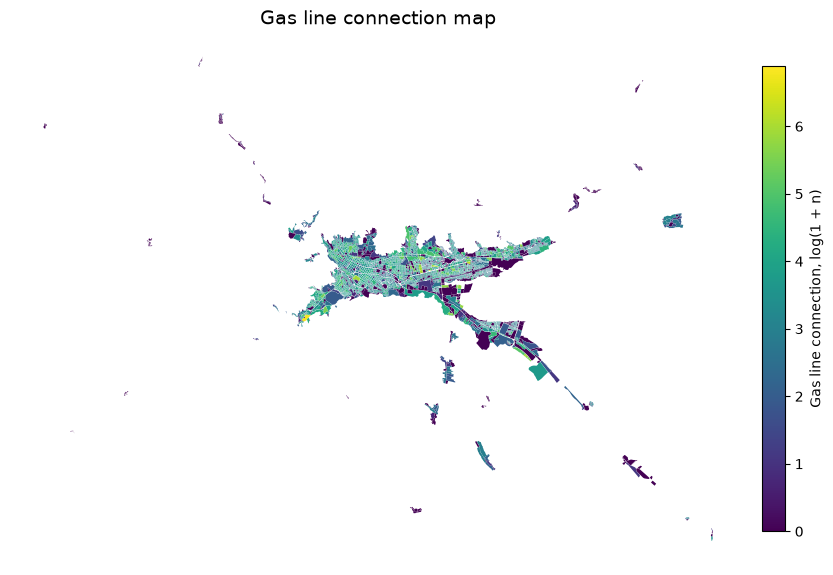

In [15]:
# Plot
fig, ax = plt.subplots(figsize=(10, 8))
# plot without automatic colorbar
gdf.plot(column='TP19_GAS_1_Log', cmap='viridis', ax=ax)

# Plot with custom colorbar
sm = plt.cm.ScalarMappable(cmap='viridis')
sm.set_array(gdf['TP19_GAS_1_Log'])
cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)  # fraction controls the size of the colorbar
cbar.set_label("Gas line connection, log(1 + n)")

ax.set_title("Gas line connection map", fontsize=14)
ax.set_axis_off()
plt.show()